# Notebook 3 - Modèle MÉSO : quelles entreprises inspecter en priorité ?

**Question :** à partir de ce que l'on sait d'une entreprise **cette année**, peut-on prédire qu'elle sera **prioritaire l'année prochaine** ?

**Entreprise prioritaire** (critère métier) = au moins **2 accidents** OU au moins **1 décès** dans l'année.

**Principe important :** on utilise uniquement des informations connues *avant* l'année prédite (année N → prédiction pour N+1). Sinon, le modèle « tricherait » en voyant les accidents qu'il doit justement prédire.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110

ent = pd.read_parquet("data/entreprises_propre.parquet")
sin = pd.read_parquet("data/sinistres_propre.parquet")

## 1. Construire la table d'apprentissage

### 1.1 Nombre d'accidents et de décès par entreprise et par année

In [2]:
sin = sin.dropna(subset=["ANNEE_ACCIDENT"])
sin["deces"] = (sin["MORT_APRES_AT"] == "OUI").astype(int)

par_an = sin.groupby(["ENTREPRISE_ID", "ANNEE_ACCIDENT"]).agg(
    nb_accidents=("SINISTRE_ID", "count"),
    nb_deces=("deces", "sum"),
).reset_index()
par_an = par_an.rename(columns={"ANNEE_ACCIDENT": "ANNEE"})
par_an["ANNEE"] = par_an["ANNEE"].astype(int)
par_an.head()

,ENTREPRISE_ID,ANNEE,nb_accidents,nb_deces
0,ENT_0001B5BA7F8911AFD0A8F51E44E92BE9,1966,1,0
1,ENT_0001F423CC2EF0CDDC32ECC3A434A5E8,1989,1,0
2,ENT_0001F423CC2EF0CDDC32ECC3A434A5E8,1990,1,0
3,ENT_0001F423CC2EF0CDDC32ECC3A434A5E8,1996,1,0
4,ENT_0001F423CC2EF0CDDC32ECC3A434A5E8,1997,2,0


### 1.2 Variables explicatives pour l'année N

* les caractéristiques de l'entreprise : effectif, masse salariale, statut, ancienneté ;
* le nombre d'accidents **pendant l'année N** ;
* le nombre d'accidents et de décès **avant l'année N** (tout l'historique depuis 1965).

In [3]:
df = ent[ent["ANNEE"] <= 2025].copy()
df["anciennete"] = (df["ANNEE"] - df["DATE_IMMATRICULATION_ANNEE"]).clip(lower=0)

# accidents de l'année N
df = df.merge(par_an, on=["ENTREPRISE_ID", "ANNEE"], how="left")
df = df.rename(columns={"nb_accidents": "accidents_annee", "nb_deces": "deces_annee"})

# historique : accidents et décès avant l'année N
historiques = []
for annee in [2022, 2023, 2024, 2025]:
    h = par_an[par_an["ANNEE"] < annee].groupby("ENTREPRISE_ID")[["nb_accidents", "nb_deces"]].sum()
    h["ANNEE"] = annee
    historiques.append(h.reset_index())
historique = pd.concat(historiques).rename(columns={"nb_accidents": "accidents_avant", "nb_deces": "deces_avant"})
df = df.merge(historique, on=["ENTREPRISE_ID", "ANNEE"], how="left")

### 1.3 La cible : l'entreprise est-elle prioritaire l'année N+1 ?

In [4]:
cible = par_an.copy()
cible["prioritaire"] = ((cible["nb_accidents"] >= 2) | (cible["nb_deces"] >= 1)).astype(int)
cible["ANNEE"] = cible["ANNEE"] - 1             # l'accident de N+1 est rattaché à la ligne de l'année N
df = df.merge(cible[["ENTREPRISE_ID", "ANNEE", "prioritaire"]], on=["ENTREPRISE_ID", "ANNEE"], how="left")

# une entreprise absente de la table des sinistres n'a eu aucun accident
colonnes_a_zero = ["accidents_annee", "deces_annee", "accidents_avant", "deces_avant", "prioritaire"]
df[colonnes_a_zero] = df[colonnes_a_zero].fillna(0)

print("Taille de la table :", df.shape)
print("% d'entreprises prioritaires l'année suivante :")
print((df.groupby("ANNEE")["prioritaire"].mean() * 100).round(2))

Taille de la table : (267140, 12)
% d'entreprises prioritaires l'année suivante :
ANNEE
2022    0.99
2023    0.97
2024    0.96
2025    0.83
Name: prioritaire, dtype: float64


**Lecture :** chaque année, environ **1 % des entreprises** deviennent prioritaires l'année suivante (environ 650 à 700 entreprises sur ~70 000). C'est un événement **rare** : on va chercher une aiguille dans une botte de foin. Le taux de 2025 est plus bas (0,83 %) parce que **2026 n'est pas finie** : on n'utilise donc pas 2025 pour évaluer le modèle.

## 2. Le lien entre passé et futur

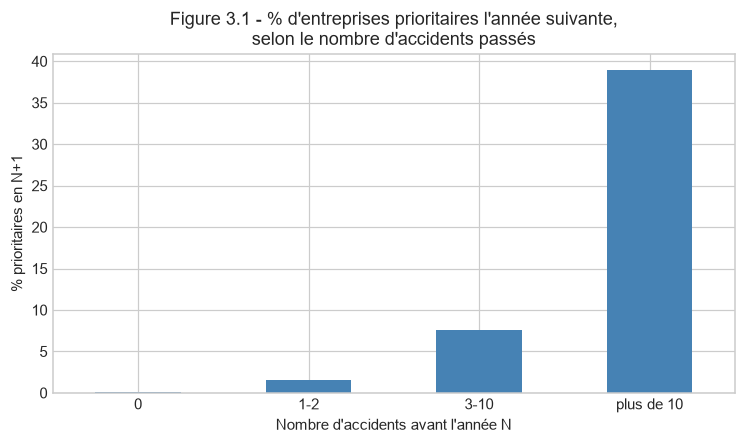

,nb d'entreprises,% prioritaires en N+1
classe_historique,,
0,244364,0.1
1-2,13539,1.6
3-10,5157,7.6
plus de 10,4080,38.9


In [5]:
df["classe_historique"] = pd.cut(df["accidents_avant"], bins=[-1, 0, 2, 10, 100000],
                                 labels=["0", "1-2", "3-10", "plus de 10"])
taux = df.groupby("classe_historique", observed=True)["prioritaire"].mean() * 100

taux.plot(kind="bar", figsize=(8, 4), color="steelblue", rot=0)
plt.title("Figure 3.1 - % d'entreprises prioritaires l'année suivante,\nselon le nombre d'accidents passés")
plt.xlabel("Nombre d'accidents avant l'année N")
plt.ylabel("% prioritaires en N+1")
plt.show()

pd.DataFrame({"nb d'entreprises": df["classe_historique"].value_counts().sort_index(),
              "% prioritaires en N+1": taux.round(1)})

**Commentaire - Figure 3.1 :** le **passé prédit fortement le futur**. Une entreprise sans aucun accident passé n'a presque aucune chance de devenir prioritaire. Celles qui ont eu **plus de 10 accidents** dans le passé deviennent prioritaires l'année suivante dans **près de 40 % des cas**. L'historique des sinistres est donc la variable la plus importante, et la base de comparaison naturelle pour notre modèle.

## 3. Préparer les données pour le modèle

**Découpage dans le temps** (et non au hasard) :
* **entraînement** : années 2022 et 2023 (pour prédire 2023 et 2024) ;
* **test** : année 2024 (pour prédire 2025, la dernière année complète).

**Test statistique (H) - l'historique d'accidents est-il lié au fait de devenir prioritaire ?**

La Figure 3.1 suggère un lien. On le teste formellement :
* **H₀** : devenir prioritaire en N+1 est **indépendant** de la classe d'historique d'accidents ;
* **H₁** : il en **dépend** ;
* **Test** : χ² d'indépendance + V de Cramér (taille d'effet).

In [6]:
table_hist = pd.crosstab(df["classe_historique"], df["prioritaire"])
chi2, p, dof, _ = stats.chi2_contingency(table_hist)
v = np.sqrt(chi2 / (table_hist.values.sum() * (min(table_hist.shape) - 1)))
print(f"chi2 = {chi2:.0f}   dof = {dof}   p-value = {p:.2e}   V de Cramer = {v:.3f}")
print("-> H0 rejetée : l'historique est fortement lié au risque futur" if p < 0.05 else "-> H0 conservée")

chi2 = 67677   dof = 3   p-value = 0.00e+00   V de Cramer = 0.503
-> H0 rejetée : l'historique est fortement lié au risque futur


**Résultat :** p-value ≪ 0,05 et V de Cramér élevé → **on rejette H₀**. L'historique d'accidents est un **prédicteur fort** du risque futur. C'est pourquoi il constitue à la fois la **variable clé** du modèle et la **référence** (« règle simple ») que le modèle doit battre.

In [7]:
variables = ["CLASSE_EFFECTIF", "CLASSE_MASSE_SALARIALE", "STATUT_ENTREPRISE", "anciennete",
             "accidents_annee", "deces_annee", "accidents_avant", "deces_avant"]

X = pd.get_dummies(df[variables], dtype=int)
y = df["prioritaire"]

train = df["ANNEE"].isin([2022, 2023])
test = df["ANNEE"] == 2024

X_train, y_train = X[train], y[train]
X_test, y_test = X[test], y[test]
print("Entraînement :", X_train.shape, " - positifs :", int(y_train.sum()))
print("Test         :", X_test.shape, " - positifs :", int(y_test.sum()))

Entraînement : (127998, 27)  - positifs : 1255
Test         : (69775, 27)  - positifs : 672


## 4. Choix du modèle : pourquoi le gradient boosting (XGBoost) ?

Les données ont des caractéristiques qui **orientent fortement** le choix :
* **tabulaires et hétérogènes** : classes ordinales (effectif, masse salariale), comptages (accidents, décès), variables catégorielles (statut) ;
* **interactions non linéaires** : le risque dépend du *croisement* taille × historique (une PME avec 10 accidents ≠ une grande entreprise avec 10 accidents) ;
* **cible très rare** (~1 %) : il faut un modèle qui gère le déséquilibre ;
* besoin d'**explicabilité** (l'inspecteur doit comprendre *pourquoi* une entreprise est ciblée).

| Candidat | Adapté ? | Raison |
|---|---|---|
| **Règle « plus d'accidents passés »** | référence | simple et parlante, mais ignore les interactions → **plafonne** (cf. courbe de gain) |
| **Régression logistique** | moyen | linéaire : il faut créer à la main les croisements et les seuils ; capte mal les effets de seuil des comptages |
| **Forêt aléatoire** | bon | gère interactions et non-linéarités, mais optimise moins bien le **classement** d'une cible très rare |
| **Gradient boosting (XGBoost)** | **retenu** | référence sur données **tabulaires déséquilibrées** ; corrige séquentiellement ses erreurs (optimise le classement) ; `scale_pos_weight` pour la rareté ; valeurs manquantes gérées nativement ; **SHAP** pour expliquer chaque score |

Pour ne pas se contenter d'affirmer, on **compare empiriquement** XGBoost à la règle, à la régression logistique et à la forêt aléatoire (section 5). Le déséquilibre (~1 %) est traité par `scale_pos_weight`.

In [8]:
poids = (y_train == 0).sum() / (y_train == 1).sum()

modele = xgb.XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    scale_pos_weight=poids, subsample=0.8, colsample_bytree=0.8, random_state=42,
)
modele.fit(X_train, y_train)
proba_test = modele.predict_proba(X_test)[:, 1]

# Modèles de comparaison : logistique et forêt n'acceptent pas les NaN (anciennete),
# on impute par la médiane (XGBoost, lui, garde les données brutes avec NaN).
med = X_train.median()
X_train_f, X_test_f = X_train.fillna(med), X_test.fillna(med)

logit = LogisticRegression(class_weight="balanced", max_iter=1000)
logit.fit(X_train_f, y_train)
proba_logit = logit.predict_proba(X_test_f)[:, 1]

foret = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=20,
                               class_weight="balanced", n_jobs=-1, random_state=42)
foret.fit(X_train_f, y_train)
proba_foret = foret.predict_proba(X_test_f)[:, 1]
print("Modèles entraînés : XGBoost, régression logistique, forêt aléatoire")

Modèles entraînés : XGBoost, régression logistique, forêt aléatoire


## 5. Évaluation

On compare le modèle à une **règle simple** : « inspecter les entreprises qui ont eu le plus d'accidents jusqu'ici ». Le modèle n'est utile que s'il fait mieux que cette règle.

In [9]:
score_regle = X_test["accidents_annee"] + X_test["accidents_avant"]

modeles_eval = {
    "Règle simple (historique)": score_regle,
    "Régression logistique": proba_logit,
    "Forêt aléatoire": proba_foret,
    "XGBoost": proba_test,
}
resultats = pd.DataFrame({
    "AUC-ROC": [roc_auc_score(y_test, s) for s in modeles_eval.values()],
    "AUC-PR": [average_precision_score(y_test, s) for s in modeles_eval.values()],
}, index=list(modeles_eval)).round(3)
print("AUC-PR d'un tirage au hasard :", round(y_test.mean(), 3))
resultats

AUC-PR d'un tirage au hasard : 0.01


,AUC-ROC,AUC-PR
Règle simple (historique),0.948,0.475
Régression logistique,0.990,0.748
Forêt aléatoire,0.991,0.744
XGBoost,0.990,0.759


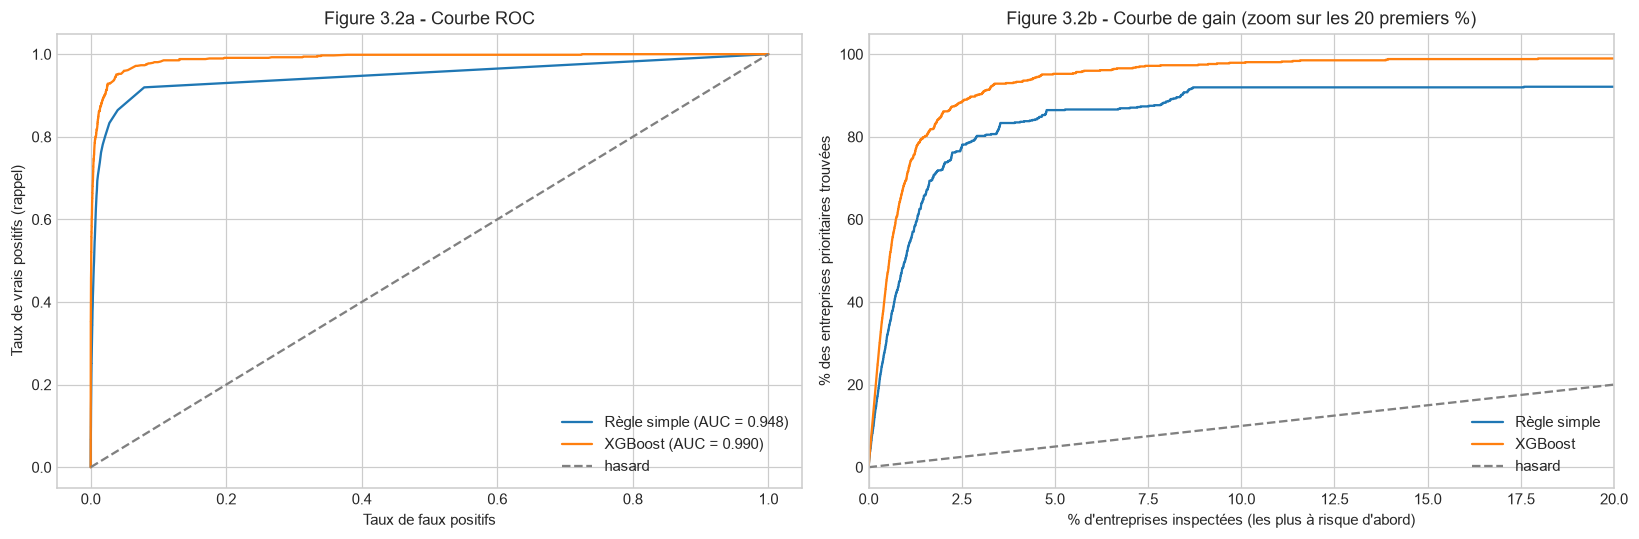

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Courbe ROC
for score, nom in [(score_regle, "Règle simple"), (proba_test, "XGBoost")]:
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[0].plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, score):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="hasard")
axes[0].set_title("Figure 3.2a - Courbe ROC")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].legend()

# Courbe de gain : si on inspecte les x % d'entreprises les mieux classées, quel % des prioritaires trouve-t-on ?
for score, nom in [(score_regle, "Règle simple"), (proba_test, "XGBoost")]:
    ordre = np.argsort(-np.asarray(score), kind="stable")
    trouves = np.cumsum(y_test.values[ordre]) / y_test.sum() * 100
    part_inspectee = np.arange(1, len(ordre) + 1) / len(ordre) * 100
    axes[1].plot(part_inspectee, trouves, label=nom)
axes[1].plot([0, 100], [0, 100], "--", color="grey", label="hasard")
axes[1].set_xlim(0, 20)
axes[1].set_title("Figure 3.2b - Courbe de gain (zoom sur les 20 premiers %)")
axes[1].set_xlabel("% d'entreprises inspectées (les plus à risque d'abord)")
axes[1].set_ylabel("% des entreprises prioritaires trouvées")
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
tableau = []
for pct in [1, 2, 5, 10]:
    n = int(len(y_test) * pct / 100)
    ligne = {"% inspecté": pct, "nb d'entreprises inspectées": n}
    for score, nom in [(score_regle, "Règle simple"), (proba_test, "XGBoost")]:
        top = np.argsort(-np.asarray(score), kind="stable")[:n]
        ligne[f"{nom} : % des prioritaires trouvées"] = round(y_test.values[top].sum() / y_test.sum() * 100, 1)
    tableau.append(ligne)
pd.DataFrame(tableau).set_index("% inspecté")

,nb d'entreprises inspectées,Règle simple : % des prioritaires trouvées,XGBoost : % des prioritaires trouvées
% inspecté,,,
1,697,50.7,69.5
2,1395,72.5,85.9
5,3488,86.5,95.2
10,6977,92.0,97.9


**Commentaire - Figure 3.2 et tableau :**
* La **règle simple** est déjà très bonne en AUC-ROC (~0,95), car l'historique prédit fortement l'avenir (test H ci-dessus).
* Mais sur la métrique qui compte pour une cible rare, l'**AUC-PR**, **XGBoost obtient le meilleur score (~0,76)**, devant la régression logistique et la forêt aléatoire (~0,75), toutes deux déjà très au-dessus de la règle simple (~0,48). C'est la justification **empirique** du choix de XGBoost, en plus de la justification théorique de la section 4.
* L'**AUC-PR** est la bonne métrique ici : au hasard elle vaudrait ~0,01 (le taux de positifs), contre ~0,76 pour XGBoost.
* **Concrètement (courbe de gain) :** en inspectant **1 % des entreprises**, XGBoost retrouve une **nettement plus grande part** des entreprises prioritaires que la règle simple (voir tableau ci-dessous).
* La règle simple plafonne, car certaines entreprises deviennent prioritaires **sans** historique d'accidents : XGBoost les repère grâce aux autres informations (taille, masse salariale, statut).

➡️ Même métier, meilleur ciblage : à nombre de contrôles égal, on trouve beaucoup plus d'entreprises à risque.

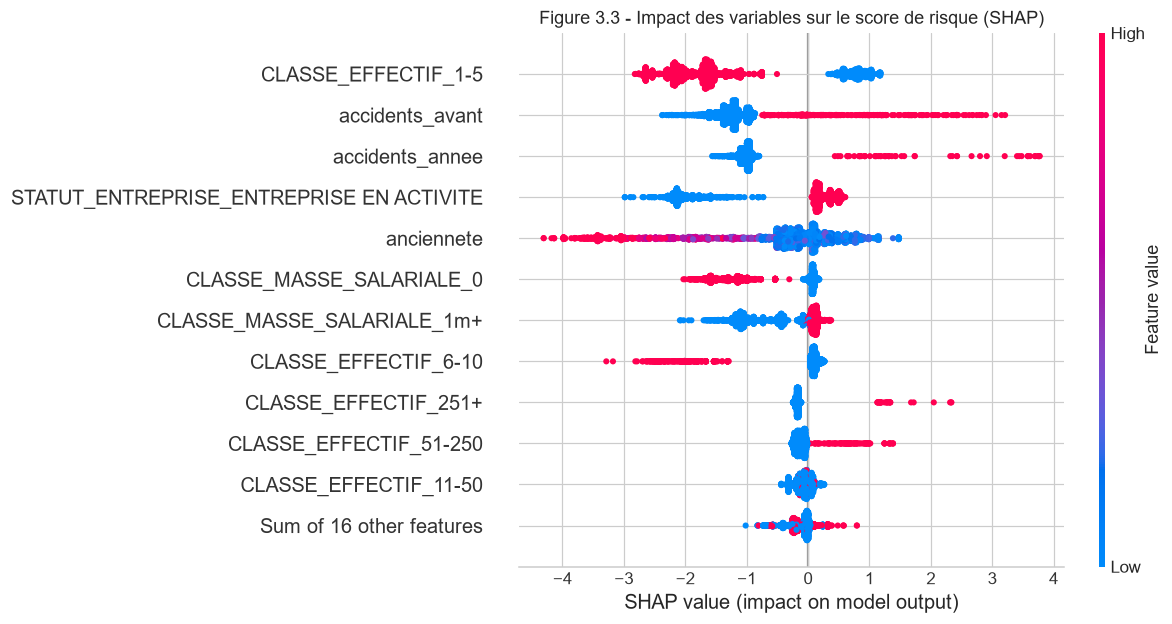

In [12]:
echantillon = X_test.sample(3000, random_state=42)
explainer = shap.TreeExplainer(modele)
shap_values = explainer(echantillon)

shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("Figure 3.3 - Impact des variables sur le score de risque (SHAP)")
plt.show()

**Commentaire - Figure 3.3 (SHAP) :**
* **`CLASSE_EFFECTIF_1-5` :** quand l'entreprise est très petite (point rouge = oui), le risque **baisse fortement**. Une petite entreprise a peu de salariés, donc peu d'occasions d'atteindre 2 accidents.
* **`accidents_avant` et `accidents_annee` :** plus il y a eu d'accidents (rouge), plus le risque **augmente**. C'est ce que montrait la Figure 3.1.
* **`STATUT_ENTREPRISE_EN ACTIVITE` :** une entreprise active a plus de risque qu'une entreprise suspendue ou radiée, ce qui est logique.
* **`anciennete` :** les entreprises plus anciennes (rouge) ont plutôt un risque **plus faible**, à taille égale.
* **Les grandes entreprises (`251+`, `51-250`)** augmentent le risque.

➡️ Le modèle est **cohérent avec le bon sens métier**, ce qui renforce la confiance qu'on peut lui accorder.

## 7. Liste des entreprises à inspecter en priorité

On applique le modèle aux données de **2025** pour classer les entreprises.

In [13]:
derniere = df["ANNEE"] == 2025
df.loc[derniere, "score_risque"] = modele.predict_proba(X[derniere])[:, 1]

liste = (df[derniere]
         .sort_values("score_risque", ascending=False)
         [["ENTREPRISE_ID", "CLASSE_EFFECTIF", "accidents_annee", "accidents_avant", "deces_avant", "score_risque"]]
         .head(20))
liste.to_csv("data/liste_entreprises_prioritaires.csv", index=False)
liste.round(4)

,ENTREPRISE_ID,CLASSE_EFFECTIF,accidents_annee,accidents_avant,deces_avant,score_risque
136149,ENT_5401D64C113E75E689803F86E3030202,251+,25.0,329.0,0.0,0.9998
92319,ENT_5CE7D39D85809E7D98717AD7DB3F96CE,251+,10.0,227.0,0.0,0.9998
59002,ENT_DCC96AA577429D58BA09B4A3771B0C89,251+,21.0,346.0,0.0,0.9998
935,ENT_BAD7A4DB6FC7636BBDF48D918F3F58B4,251+,55.0,1830.0,0.0,0.9998
111083,ENT_A2B89B28D8B21538175B9E05BBECDE66,251+,13.0,220.0,0.0,0.9998
58519,ENT_C489AF46051A40054B5FEC47DC211FAB,251+,66.0,560.0,0.0,0.9998
21128,ENT_C62D74E36305D3F895ACFEBE3F62D000,251+,18.0,232.0,3.0,0.9998
38317,ENT_80C3EC5FFF7A96E3BB61E742EC072C7B,251+,13.0,370.0,0.0,0.9998
4891,ENT_3E70D7B8BB3188E051B329B53A541092,251+,13.0,369.0,0.0,0.9998
67363,ENT_44C335A9F3433141FEF71FD50AAB40A6,251+,100.0,354.0,0.0,0.9998


**Commentaire :** la liste est dominée par des **grandes entreprises (251+ salariés) ayant déjà de nombreux accidents**. Leur score vaut presque 1 : elles seront très probablement prioritaires. La liste complète est enregistrée dans `data/liste_entreprises_prioritaires.csv`.

⚠️ **Limite :** le modèle prédit un **nombre** d'accidents, pas un **taux par salarié**. Les grandes entreprises sont donc naturellement en tête. Pour repérer les entreprises *anormalement* dangereuses à taille égale, il faudrait l'**effectif exact** de chaque entreprise (on n'a qu'une classe), pour calculer un taux de fréquence.

**Conclusion du modèle méso :** en inspectant 1 % des entreprises choisies par le modèle, on trouve près de 70 % des entreprises prioritaires de l'année suivante.

## 8. Sauvegarde du modèle

On enregistre le modèle et la **liste des colonnes** utilisées : pour scorer de nouvelles entreprises, il faudra préparer les données avec exactement les mêmes colonnes.

In [14]:
import joblib

joblib.dump({"modele": modele, "colonnes": list(X.columns)}, "modeles/meso_xgboost_entreprises.joblib")
print("Modèle sauvegardé dans modeles/meso_xgboost_entreprises.joblib")

# Exemple de rechargement
sauvegarde = joblib.load("modeles/meso_xgboost_entreprises.joblib")
scores = sauvegarde["modele"].predict_proba(X_test[sauvegarde["colonnes"]].head(5))[:, 1]
print("Scores de 5 entreprises :", scores.round(4))

Modèle sauvegardé dans modeles/meso_xgboost_entreprises.joblib
Scores de 5 entreprises : [0.0001 0.0007 0.0003 0.0002 0.    ]
